In [9]:
import numpy as np
import matplotlib.pyplot as plt

stack_aia = np.load("phi_N_stack_aia.npy")
stack_vp = np.load("phi_N_stack_vp.npy")

In [10]:
def centered(p):
    """Wrapped phase -> zero-mean real map around its circular mean (sign flip -> negation)."""
    z = np.exp(1j * p)
    x = np.angle(z * np.conj(z.mean()))
    return x - x.mean()

def _peak_offset(cm, c0, cp):
    d = cm - 2 * c0 + cp
    return 0.0 if d == 0 else 0.5 * (cm - cp) / d

def signed_shift(ref, img, max_shift=40):
    """Sub-pixel (dy, dx) rolling img onto ref, and the signed normalized correlation r at that shift.
    r < 0 means img has the opposite phase sign."""
    c = np.fft.ifft2(np.fft.fft2(ref) * np.fft.fft2(img).conj()).real
    c = np.fft.fftshift(c) / (np.linalg.norm(ref) * np.linalg.norm(img))
    H, W = c.shape; cy, cx = H // 2 - max_shift, W // 2 - max_shift
    win = np.abs(c[cy:cy + 2 * max_shift + 1, cx:cx + 2 * max_shift + 1])
    iy, ix = np.unravel_index(win.argmax(), win.shape)
    py, px = cy + iy, cx + ix
    dy = iy - max_shift + _peak_offset(*np.abs(c[py - 1:py + 2, px]))
    dx = ix - max_shift + _peak_offset(*np.abs(c[py, px - 1:px + 2]))
    return dy, dx, c[py, px]

def register_wavelengths(ref_stack, roi, max_shift=40):
    """Chain neighbouring wavelengths of ref_stack (wvl, Y, X): cumulative sign and shift relative to wvl 0."""
    X = [centered(p[roi]) for p in ref_stack]
    signs, shifts, corr = [1], [np.zeros(2)], [1.0]
    for k in range(1, len(X)):
        dy, dx, r = signed_shift(X[k - 1], X[k], max_shift)
        signs.append(signs[-1] * int(np.sign(r)))
        shifts.append(shifts[-1] + (dy, dx))
        corr.append(r)
    return np.array(signs), np.array(shifts), np.array(corr)

def signs_vs_reference(stack, ref_stack, roi):
    """Sign of every (N, wvl) map relative to ref_stack at the same wavelength (zero shift)."""
    r = np.empty(stack.shape[:2])
    for w in range(stack.shape[1]):
        x_ref = centered(ref_stack[w][roi])
        for n in range(stack.shape[0]):
            x = centered(stack[n, w][roi])
            r[n, w] = (x * x_ref).sum() / np.sqrt((x**2).sum() * (x_ref**2).sum())
    return np.sign(r).astype(int), r

def apply_registration(stack, signs, shifts):
    """Flip signs (N, wvl), roll each wavelength by integer shifts (wvl, 2), crop to the common valid window."""
    N, L, H, W = stack.shape
    y0, x0 = shifts.max(0).clip(min=0)
    y1, x1 = np.array([H, W]) + shifts.min(0).clip(max=0)
    out = np.empty((N, L, y1 - y0, x1 - x0), stack.dtype)
    for w, (dy, dx) in enumerate(shifts):
        out[:, w] = stack[:, w, y0 - dy:y1 - dy, x0 - dx:x1 - dx] * signs[:, w, None, None].astype(stack.dtype)
    return out

In [11]:
roi = (slice(250, 1250), slice(1000, 2000))
ref = stack_aia[-1]                                   # largest N of AIA: reference for both stacks

s_wvl, shifts_f, r_wvl = register_wavelengths(ref, roi)
shifts = np.rint(shifts_f).astype(int)

s_aia, r_aia = signs_vs_reference(stack_aia, ref, roi)
s_vp, r_vp = signs_vs_reference(stack_vp, ref, roi)
signs_aia = s_aia * s_wvl[None]
signs_vp = s_vp * s_wvl[None]

print("min |r| neighbour wvl:", np.abs(r_wvl[1:]).min().round(3))
print("min |r| vs ref  AIA:", np.abs(r_aia).min().round(3), " VP:", np.abs(r_vp).min().round(3))

stack_aia_reg = apply_registration(stack_aia, signs_aia, shifts)
stack_vp_reg = apply_registration(stack_vp, signs_vp, shifts)
print(stack_aia_reg.shape)

min |r| neighbour wvl: 0.779
min |r| vs ref  AIA: 0.918  VP: 0.011
(11, 41, 2183, 3288)


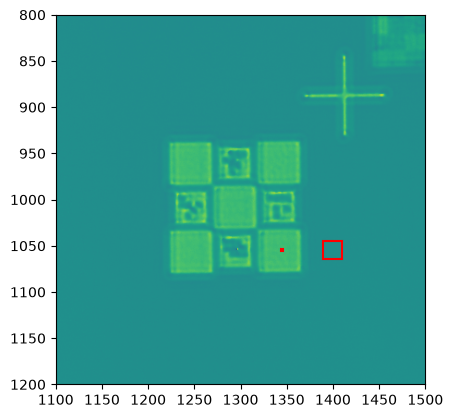

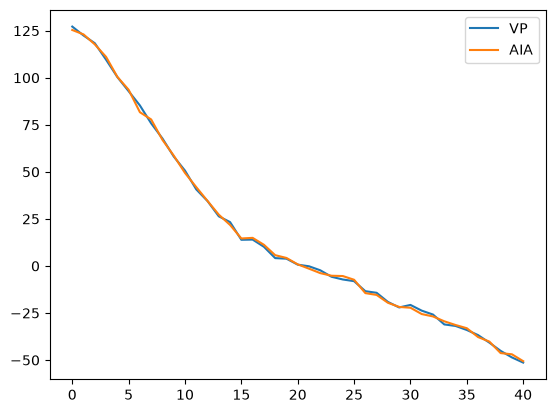

In [54]:
from matplotlib.patches import Rectangle
side = 20

xc1 = 1345
yc1 = 1055
side1 = 2

xc2 = 1400
yc2 = 1055
side2 = side

squares = [(xc1 - side1//2, yc1 - side1//2, side1), (xc2 - side2//2, yc2 - side2//2, side2)]   # (x, y, side) in pixels

fig, ax = plt.subplots()
ax.imshow(stack_vp_reg[-1, 8])
for x, y, s in squares:
    ax.add_patch(Rectangle((x - 0.5, y - 0.5), s, s, fill=False, edgecolor="red", linewidth=1.5))
ax.set_xlim(1100, 1500)
ax.set_ylim(1200, 800)   # imshow has y pointing down
plt.show()

# Average over
x1, y1, s1 = squares[0]
x2, y2, s2 = squares[1]
stack_vp_res = stack_vp_reg[:,:,y1:y1+s1,x1:x1+s1].mean(axis=(-2, -1)) - stack_vp_reg[:,:,y2:y2+s2,x2:x2+s2].mean(axis=(-2, -1))
stack_aia_res = stack_aia_reg[:,:,y1:y1+s1,x1:x1+s1].mean(axis=(-2, -1)) - stack_aia_reg[:,:,y2:y2+s2,x2:x2+s2].mean(axis=(-2, -1))
plt.figure()
plt.plot(stack_vp_res[5]*180/np.pi, label="VP")
plt.plot(stack_aia_res[5]*180/np.pi, label="AIA")
plt.legend()
plt.show()

(-0.5, 0.5)

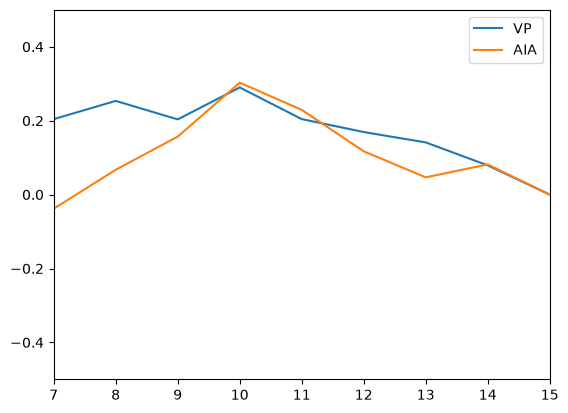

In [53]:
n = np.arange(5, 16)
plt.figure()
plt.plot(n, (stack_vp_res - stack_vp_res[-1,:]).mean(axis=-1)*180/np.pi, label="VP")
plt.plot(n, (stack_aia_res - stack_aia_res[-1,:]).mean(axis=-1)*180/np.pi, label="AIA")
plt.legend()
plt.xlim(7, 15)
plt.ylim([-0.5, 0.5])